# 08. Transaction – Time theo Label

## Câu hỏi

- Mua càng gần cutoff thì label càng dễ bằng 1 không?
- Khách hoạt động nhiều ngày trong 90 ngày trước cutoff có propensity cao hơn không?
- Hoạt động qua nhiều tuần có liên quan label không?
- Khách có chu kỳ mua ngắn có propensity cao hơn không?
- Khách mua đều có khác khách mua thất thường không?

Tất cả transaction dùng để tạo feature đều nằm trước cutoff. Active days, active weeks và gap được tính trong `[cutoff-90, cutoff-1]`.

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path

import matplotlib.pyplot as plt

from propensity.eda.transaction_time_label import (
    load_transaction_time_label_report,
)
from propensity.eda.transaction_time_label_plots import (
    plot_transaction_time_boxplots,
)


## 1. Build leakage-safe temporal features

In [2]:
project_root = Path.cwd().resolve()
if project_root.name == "notebooks":
    project_root = project_root.parent

label_path = project_root / "data" / "processed" / "purchase_propensity_t90_h7_step7" / "household_cutoff_labels.parquet"
transaction_path = project_root / "data" / "raw" / "Dunnhumby" / "transaction_data.csv"

report = load_transaction_time_label_report(
    label_path,
    transaction_path,
    observation_days=90,
)


## 2. Định nghĩa feature

| Feature | Định nghĩa |
|---|---|
| `days_since_last_purchase` | `cutoff_day - last_purchase_day`, dùng toàn bộ lịch sử trước cutoff |
| `active_days_90d` | Số purchase days distinct trong 90 ngày trước cutoff |
| `active_weeks_90d` | Số `WEEK_NO` distinct có mua trong 90 ngày trước cutoff |
| `median_interpurchase_gap_days_90d` | Median gap giữa các purchase days liên tiếp trong cửa sổ |
| `interpurchase_gap_std_days_90d` | Standard deviation của gap; null nếu chưa đủ hai gap |

In [3]:
report.summary_by_label

,feature,label,n_observations,missing_rate,p10,q1,median,q3,p90
0,days_since_last_purchase,0,94821,0.000000,2.000000,5.000000,16.000000,50.000000,128.000000
1,days_since_last_purchase,1,107423,0.000000,1.000000,2.000000,4.000000,9.000000,18.800000
2,active_days_90d,0,94821,0.000000,0.000000,1.000000,4.000000,9.000000,14.000000
3,active_days_90d,1,107423,0.000000,4.000000,8.000000,15.000000,24.000000,36.000000
4,active_weeks_90d,0,94821,0.000000,0.000000,1.000000,4.000000,7.000000,10.000000
5,active_weeks_90d,1,107423,0.000000,4.000000,7.000000,10.000000,12.000000,13.000000
6,median_interpurchase_gap_days_90d,0,70555,0.255914,3.000000,5.000000,8.000000,15.000000,28.000000
7,median_interpurchase_gap_days_90d,1,104628,0.026019,2.000000,3.000000,4.000000,7.000000,12.000000
8,interpurchase_gap_std_days_90d,0,61340,0.353097,2.828427,4.281744,6.968979,11.321194,17.925773
9,interpurchase_gap_std_days_90d,1,102238,0.048267,1.564457,2.308402,3.700776,6.210590,10.263203


## 3. Box plot theo label

Whisker hiển thị P5–P95 và outlier được ẩn để tập trung vào phần lớn phân phối. Mỗi subplot giữ thang đo tự nhiên riêng.

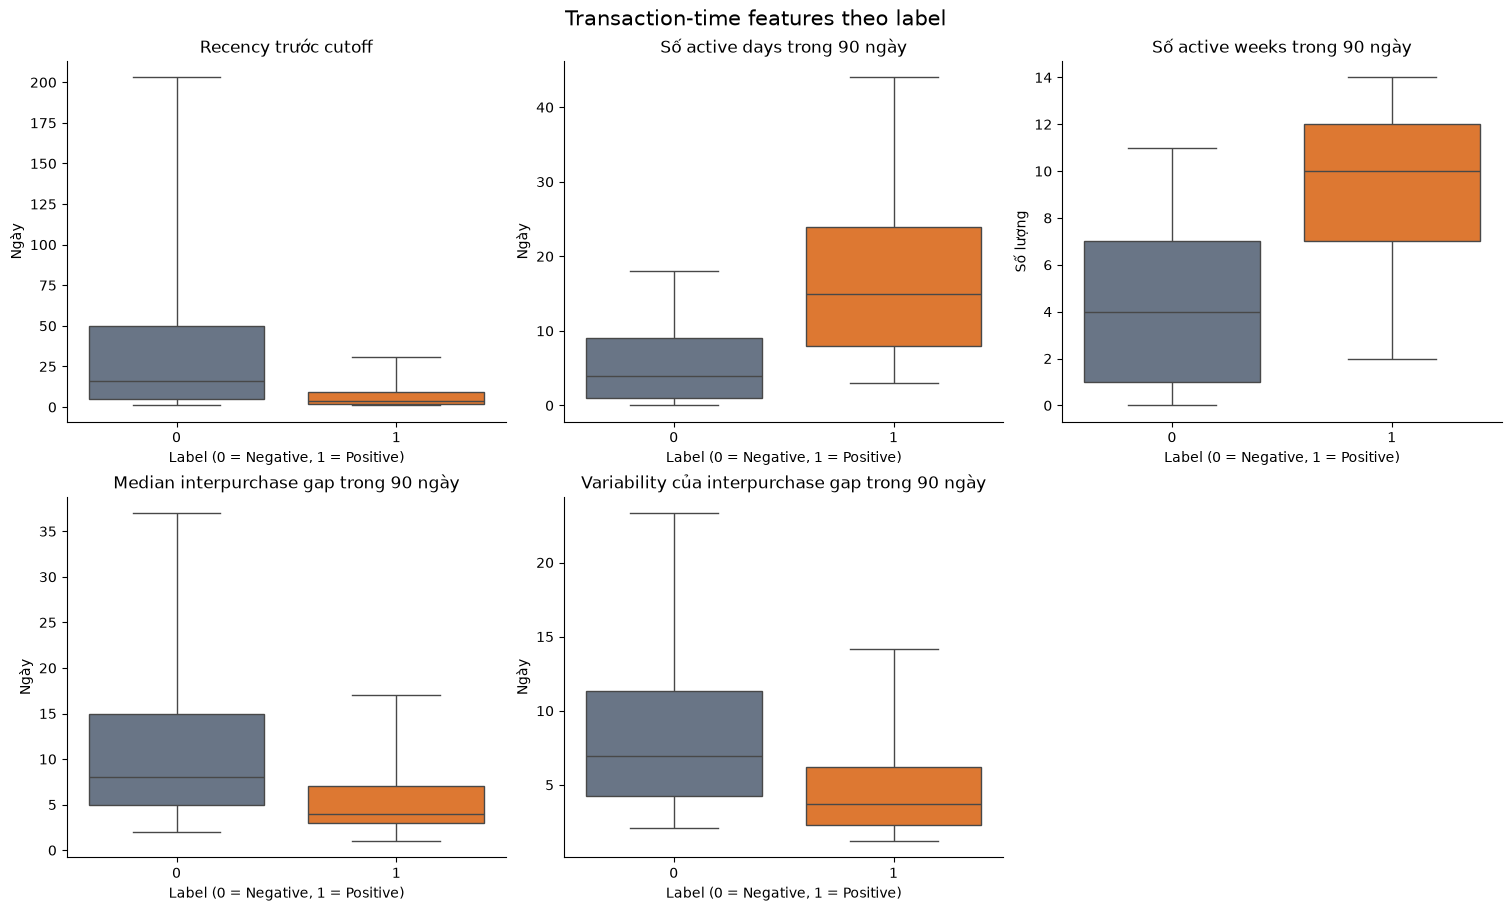

In [4]:
figure = plot_transaction_time_boxplots(report.feature_panel)
plt.show()

## Lưu ý diễn giải

- Gap được tính trên purchase days distinct; nhiều basket cùng ngày không tạo gap bằng 0.
- Gap median cần ít nhất 2 active days; variability cần ít nhất 3 active days. Vì vậy phải đọc `missing_rate` cùng box plot.
- Box plot mô tả association, không chứng minh recency hoặc frequency gây ra label dương.
- Parquet label cần được tạo lại sau khi target window đổi thành `[cutoff, cutoff+6]`.